# The $u$–$\delta$ dipole in real and redshift space

**The linear-theory prediction of $\langle\xi_{u\delta}\rangle_1$, following Nusser (2017)
and built from the Górski (1988) velocity correlation functions.**

This notebook is a *thin consumer*. Every formula below is implemented in
`src/dvcorr/theory/` — `transforms.py` (the Bessel moments), `gorski.py` (the $\Psi$
functions), `dipole.py` (the public first moment), `wide_angle.py` (exact geometry) — and
tested in `tests/test_theory.py`. Nothing here is a definition site; what the notebook adds
is the numbers, the plots, and the narrative that says which claims were checked and how
hard.

## What it establishes

1. The three ingredient functions $A$, $B$, $\Psi$ are computed correctly — against closed
   forms and against brute quadrature, per Bessel order **and** per power of $k$.
2. Górski's identity $\Psi_-=y\,\Psi'_\perp$ holds through three independent FFTLog orders.
3. The $j_2$ terms cancel **exactly** out of the dipole, for every $f$ and every $b$ — which
   is what pins the corrected sign in Nusser's eq. (17), and what the printed sign fails.
4. Both spaces collapse onto one shape, $\langle\xi^s_{u\delta_g}\rangle_1
   = \tfrac{aHf}{3}\left(b+\tfrac{3f}{5}\right)A(y)$: linear RSD is a *scale-independent*
   amplitude boost $b\to b+3f/5$.
5. Nusser's Figure 1, all five curves, with the wide-angle geometry validated by its own
   convergence rather than by eye.

## Conventions (load-bearing — every sign below follows from them)

| Symbol | Meaning |
|---|---|
| $\boldsymbol r$ | position of the **velocity** object (observer at origin) |
| $\tilde{\boldsymbol r}$ | position of the **density** point |
| $\boldsymbol y=\tilde{\boldsymbol r}-\boldsymbol r$ | pair separation, **velocity $\to$ density** |
| $\mu=\hat{\boldsymbol r}\cdot\hat{\boldsymbol y}$ | angle cosine at the velocity object |
| $\tilde\mu,\ \nu$ | wide-angle cosines; in the DOL $\tilde\mu\to\mu$, $\nu\to1$ |
| $u=\boldsymbol v\cdot\hat{\boldsymbol r}$ | observer-centred radial peculiar velocity |
| $L_\ell$ | Legendre polynomials ($P$ is reserved for $P_m(k)$) |

**Two things that are easy to conflate and are kept apart by name throughout:**

- *Orientation.* Nusser's $\boldsymbol y$ points velocity $\to$ density; this project's
  $\boldsymbol r=\boldsymbol s_V-\boldsymbol s_T$ points density $\to$ velocity. Same pair,
  same magnitude, opposite sign on every odd multipole:
  $\xi_{Tu,\ell}=(-1)^\ell\,\xi_{uT,\ell}$, applied explicitly through
  `conventions.nusser_multipole_sign`.
- *Normalisation.* Nusser uses $\langle\xi\rangle_\ell=\tfrac12\int\xi L_\ell\,d\mu$ with
  **no** $(2\ell+1)$. The community standard carries $(2\ell+1)/2$ — a factor of **3** for
  the dipole. `dipole.CONVENTION_NUSSER` / `CONVENTION_STANDARD`.

**Known typos in the paper, corrected here:** eq. (17) as printed has the wrong sign on the
$\Psi'_-$ coefficient (§4 below is the proof); eq. (15) line 2 carries a spurious duplicated
$-3\Psi'_\perp\mu$, and the correct $\xi_{wu}$ is eq. (11).

## 1. Setup

Two cosmologies, because the two questions are different. Everything *structural* — the
cancellations, the collapse, the geometry — is checked at the **MDPL2** cosmology, since
that is what the simulation-validation arm measures against. Nusser's **Figure 1** is
reproduced at his Planck 2015 fiducial.

`CosmologyConfig.__post_init__` requires `h` to agree with `conventions.HUBBLE_PARAM`, so
the Planck variant keeps $H_0=67.77$ ($h=0.6777$ against Nusser's $0.677$, a 0.1%
difference) and moves only $\Omega_m$, $\sigma_8$ and $n_s$. That is the closest legal
match, and the residual is printed rather than waved at.

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.special import gamma as gamma_fn

from dvcorr import conventions
from dvcorr.config import CosmologyConfig, growth_rate, scale_factor_hubble
from dvcorr.pipeline import galaxy_bias as gb
from dvcorr.theory import dipole, gorski, transforms, wide_angle

Z = gb.SNAPSHOT_REDSHIFT

#: The simulation-validation cosmology -- everything structural is checked here.
COSMO_MDPL2 = CosmologyConfig()

#: Nusser's Planck 2015 fiducial, as close as the h-consistency check allows.
COSMO_NUSSER = CosmologyConfig(Om0=0.31, Ode0=0.69, sigma8=0.83, ns=0.968)

AH_MDPL2 = scale_factor_hubble(COSMO_MDPL2, Z)
AH_NUSSER = scale_factor_hubble(COSMO_NUSSER, Z)
F_MDPL2 = growth_rate(COSMO_MDPL2, Z)
F_NUSSER = growth_rate(COSMO_NUSSER, Z)
B_FID = 1.0

# aH is the ONE units factor in the whole subpackage (dvcorr.config.scale_factor_hubble).
# At z = 0 it must be exactly 100 km/s per h^-1 Mpc -- the hand-computable check that it
# is H/h and not H*h, which would rescale every prediction by h**2 with no change of shape.
assert Z == 0.0, f"snapshot redshift is {Z}, not 0 -- aH = 100 no longer holds"
assert abs(AH_MDPL2 - 100.0) < 1e-12, f"aH = {AH_MDPL2!r}, expected exactly 100"
assert abs(AH_NUSSER - 100.0) < 1e-12

print(f"{'':22s}{'MDPL2':>12s}{'Nusser/Planck15':>18s}{'his value':>12s}")
for label, mdpl2, nusser, his in [
    ("Omega_m",     COSMO_MDPL2.Om0,     COSMO_NUSSER.Om0,     0.31),
    ("h",           COSMO_MDPL2.h,       COSMO_NUSSER.h,       0.677),
    ("sigma_8",     COSMO_MDPL2.sigma8,  COSMO_NUSSER.sigma8,  0.83),
    ("n_s",         COSMO_MDPL2.ns,      COSMO_NUSSER.ns,      0.968),
    ("f = Om^0.55", F_MDPL2,             F_NUSSER,             0.53),
    ("aH [km/s / h-1Mpc]", AH_MDPL2,     AH_NUSSER,            100.0),
]:
    print(f"{label:22s}{mdpl2:12.6f}{nusser:18.6f}{his:12.4f}")

print()
print(f"b (fiducial)                  = {B_FID}")
print(f"Kaiser dipole bias b + 3f/5   = {dipole.kaiser_dipole_bias(B_FID, F_NUSSER):.6f}   (Nusser cosmology)")
print(f"boost 1 + 3f/(5b)             = {dipole.dipole_boost(B_FID, F_NUSSER):.6f}")

                             MDPL2   Nusser/Planck15   his value
Omega_m                   0.307115          0.310000      0.3100
h                         0.677700          0.677700      0.6770
sigma_8                   0.822800          0.830000      0.8300
n_s                       0.960000          0.968000      0.9680
f = Om^0.55               0.522415          0.525108      0.5300
aH [km/s / h-1Mpc]      100.000000        100.000000    100.0000

b (fiducial)                  = 1.0
Kaiser dipole bias b + 3f/5   = 1.315065   (Nusser cosmology)
boost 1 + 3f/(5b)             = 1.315065


### The radial grid, and where linear theory stops being true

Linear theory is not trustworthy below $\sim20\,h^{-1}$Mpc. Curves are drawn there — the
shape is instructive — but **dashed**, and no number quoted from that region is a
prediction.

One CAMB solve per cosmology, reused everywhere below. The master integral $A(y)$ depends
on $P(k)$ alone, so a parameter scan multiplies a cached $\hat A$ rather than re-running the
transform; recomputing it per $(f,\sigma_8,b)$ would be both wasteful and would make the
collapse test tautological.

In [2]:
Y_MAX, N_Y = 150.0, 500
LINEAR_FLOOR = 20.0  # h^-1 Mpc; below this the curves are dashed

#: x-axis range shared by every RADIAL panel in this notebook, h^-1 Mpc. The grid runs
#: past it so the transforms and the tables are unaffected by a plotting choice; only the
#: view is clipped. The one panel that does NOT use this is the beta scan, whose abscissa
#: is beta = f/b and not a separation at all.
X_MIN_PLOT, X_MAX_PLOT = 0.0, 100.0

# The radii the tables below quote are put ON the grid, so a printed "y = 50.0" is
# an evaluation at 50.0 and not the nearest geomspace node to it.
QUOTED_RADII = [5.0, 10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 90.0, LINEAR_FLOOR]

# y = 0 is INCLUDED, and it is not an extrapolation: the FFTLog output grid is
# logarithmic and so can never contain zero, but every quantity has a closed form
# there -- A(0) = B(0) = Psi'(0) = Psi_-(0) = 0, and Psi_perp(0) = Psi_par(0) =
# sigma_v^2(1D). `transforms.bessel_moment` returns those directly rather than
# interpolating, so the curves below genuinely reach the origin.
# `Y_MIN` is the first POSITIVE node: the FFTLog grid's own floor, ~1/k_max.
Y_MIN = 1.0 / gb.CAMB_K_MAX
y = np.unique(np.concatenate([[0.0], np.geomspace(Y_MIN, Y_MAX, N_Y), QUOTED_RADII]))

# Ratios of two curves are 0/0 at the origin (both dipoles vanish there), so
# every ratio below is COMPUTED on this mask rather than on the full grid. The
# panels that plot such a ratio still reach x = 0, via `ratio_to_origin`.
positive = y > 0.0


def ratio_to_origin(ratio):
    """Extend a curve ratio defined on `y[positive]` down to x = 0.

    A ratio of two dipoles is 0/0 at y = 0 -- both vanish -- but the LIMIT exists
    and is nowhere near zero: numerator and denominator are the same A(y) times
    different constants, so the ratio is constant in y and the limit is that
    constant. What is prepended here is a two-point linear extrapolation of the
    MEASURED curve to y = 0, never the analytic 1 + 3f/5b: these panels exist to
    measure that number, so writing it in at the origin would make the comparison
    circular. Every statistic (mean, spread) below still comes from the measured
    `y[positive]` nodes -- the origin point is for the eye.

    Parameters
    ----------
    ratio : ndarray, shape (P,)
        A ratio of two curves, on `y[positive]`, P = positive.sum().

    Returns
    -------
    x : ndarray, shape (P + 1,)
        `y[positive]` with 0.0 prepended.
    values : ndarray, shape (P + 1,)
        `ratio` with its extrapolated y -> 0+ limit prepended.
    """
    y_pos = y[positive]
    slope = (ratio[1] - ratio[0]) / (y_pos[1] - y_pos[0])
    limit = ratio[0] - slope * y_pos[0]
    return np.concatenate([[0.0], y_pos]), np.concatenate([[limit], ratio])
below = y <= LINEAR_FLOOR
above = y >= LINEAR_FLOOR
print(f"y grid: {y.size} points, {y[0]:.0f} (exact) then {y[1]:.4f} to {y[-1]:.0f} h^-1 Mpc")

# THE two CAMB solves behind every number in this notebook.
K_MDPL2, PK_MDPL2 = gb.linear_power_spectrum(COSMO_MDPL2, Z, nonlinear=False)
K_NUSSER, PK_NUSSER = gb.linear_power_spectrum(COSMO_NUSSER, Z, nonlinear=False)
print(f"CAMB: k in [{K_MDPL2[0]:.1e}, {K_MDPL2[-1]:.1f}] h/Mpc, {K_MDPL2.size} log-spaced points")

# Cached shape integrals -- A(y) for both cosmologies, and B(y) for the Gorski work.
A_MDPL2 = transforms.a_integral(y, K_MDPL2, PK_MDPL2)
B_MDPL2 = transforms.b_integral(y, K_MDPL2, PK_MDPL2)
A_NUSSER = transforms.a_integral(y, K_NUSSER, PK_NUSSER)

print()
print(f"{'y':>6}  {'A(y)':>10}  {'B(y)':>10}   [h^-1 Mpc, MDPL2]")
for y_i in (5.0, 10.0, 20.0, 50.0, 90.0):
    j = int(np.argmin(np.abs(y - y_i)))
    print(f"{y[j]:6.1f}  {A_MDPL2[j]:10.5f}  {B_MDPL2[j]:10.5f}")

y grid: 509 points, 0 (exact) then 0.0200 to 150 h^-1 Mpc


CAMB: k in [1.0e-05, 50.0] h/Mpc, 2048 log-spaced points

     y        A(y)        B(y)   [h^-1 Mpc, MDPL2]
   5.0     2.71359     0.69145
  10.0     2.25124     0.60874
  20.0     1.52719     0.44825
  50.0     0.60786     0.20916
  90.0     0.24494     0.09796


## 2. The transforms, validated before anything is built on them

Everything reduces to one integral,

$$M_\ell^{\,p}(y)=\int_0^\infty dk\;k^{p}\,P(k)\,j_\ell(ky)$$

with four $(\ell,p)$ pairs covering the whole of Nusser §2:

$$A(y)=\frac{M_1^{\,1}}{2\pi^2},\qquad
B(y)=\frac{M_2^{\,0}}{2\pi^2\,y},\qquad
\Psi_\perp=\frac{f^2\,M_1^{-1}}{2\pi^2\,y},\qquad
\Psi_\parallel = \frac{f^2}{2\pi^2}\!\left(M_0^{\,0}-2\,\frac{M_1^{-1}}{y}\right)$$

`multipole_shape_integral` — the function the production $\zeta_1$ overlay already uses —
is the $p=1$ case, and now delegates to `transforms.bessel_moment` so the package holds one
FFTLog implementation rather than two.

### Check 1 — closed forms, per order *and* per power

A power law has an exact answer,
$\int_0^\infty x^{s-1}j_\ell(x)\,dx = 2^{s-2}\sqrt\pi\,\Gamma(\tfrac{\ell+s}{2})/\Gamma(\tfrac{\ell-s+3}{2})$
with $s=n+p+1$, converging for $-\ell<s<2$. Different $(\ell,p)$ give genuinely different
closed forms, so an $\ell=1$ answer wearing an $\ell=2$ label cannot pass this. The index
$n$ is chosen per case only to keep $s$ inside the convergence strip.

In [3]:
def closed_form(y_values, index, ell, k_power):
    """Int dk k^k_power k^index j_ell(k y), exact. Converges for -ell < s < 2."""
    s = index + k_power + 1.0
    return y_values ** (-s) * 2.0 ** (s - 2.0) * np.sqrt(np.pi) * (
        gamma_fn((ell + s) / 2.0) / gamma_fn((ell - s + 3.0) / 2.0)
    )


Y_CHECK = np.array([5.0, 10.0, 20.0, 50.0, 90.0])
CASES = [
    (0,  0, -0.5, "M_0^0   -> Psi_par"),
    (0,  1, -1.0, "M_0^1   (density monopole)"),
    (1,  1, -1.0, "M_1^1   -> A"),
    (2,  0, -1.0, "M_2^0   -> B"),
    (1, -1, -0.5, "M_1^-1  -> Psi_perp"),
    (3,  1, -1.0, "M_3^1   (RSD octupole)"),
]

print("Power-law P(k) = k^n, FFTLog vs the exact Mellin answer:\n")
print(f"  {'case':28s}{'n':>6}{'q':>8}{'max |frac dev|':>18}")
worst_closed = 0.0
for ell, k_power, index, name in CASES:
    k_pow_grid = np.geomspace(1e-6, 1e4, 4096)
    pk_pow = k_pow_grid**index
    got = transforms.bessel_moment(Y_CHECK, k_pow_grid, pk_pow, ell=ell, k_power=k_power)
    exact = closed_form(Y_CHECK, index, ell, k_power)
    dev = float(np.max(np.abs(got / exact - 1.0)))
    worst_closed = max(worst_closed, dev)
    q = transforms.fftlog_tilt(k_pow_grid, pk_pow, ell, k_power)
    print(f"  {name:28s}{index:6.1f}{q:8.2f}{dev:18.3e}")
    assert dev < 1e-9, f"{name} failed at {dev:.3e}"

print(f"\n  worst case over all six: {worst_closed:.3e}   -> every (ell, k_power) pair is exact")

Power-law P(k) = k^n, FFTLog vs the exact Mellin answer:

  case                             n       q    max |frac dev|
  M_0^0   -> Psi_par            -0.5    0.50         1.491e-13
  M_0^1   (density monopole)    -1.0    1.00         2.363e-12
  M_1^1   -> A                  -1.0    1.00         2.322e-12
  M_2^0   -> B                  -1.0    0.00         1.110e-15
  M_1^-1  -> Psi_perp           -0.5   -0.50         1.478e-13
  M_3^1   (RSD octupole)        -1.0    1.00         2.335e-12

  worst case over all six: 2.363e-12   -> every (ell, k_power) pair is exact


### Check 2 — brute quadrature on the real $P_{\rm lin}$

A closed form only tests the transform against an idealised input. This tests it against
the actual CAMB spectrum, with its BAO wiggles and its broken power-law asymptotics, using
a dense trapezoid rule (1.2M nodes: log-spaced where the integrand is smooth, linear where
$j_\ell(ky)$ oscillates). `bessel_moment_quadrature` lives in the library so this check and
the test suite run the same reference.

In [4]:
Y_QUAD = np.array([10.0, 50.0])
print("FFTLog vs brute quadrature on the MDPL2 CAMB P_lin:\n")
print(f"  {'case':28s}{'y':>6}{'quadrature':>16}{'FFTLog':>16}{'frac dev':>13}")
worst_quad = 0.0
for ell, k_power, _, name in CASES:
    fft = transforms.bessel_moment(Y_QUAD, K_MDPL2, PK_MDPL2, ell=ell, k_power=k_power)
    brute = transforms.bessel_moment_quadrature(Y_QUAD, K_MDPL2, PK_MDPL2, ell=ell, k_power=k_power)
    for y_i, b_i, f_i in zip(Y_QUAD, brute, fft):
        print(f"  {name:28s}{y_i:6.0f}{b_i:16.6f}{f_i:16.6f}{f_i / b_i - 1.0:+13.2e}")
    worst_quad = max(worst_quad, float(np.max(np.abs(fft / brute - 1.0))))

print(f"\n  worst |frac dev|: {worst_quad:.2e}  -- this is the quadrature's own accuracy,")
print("  not the FFTLog's; the closed-form check above puts the transform at ~1e-12.")

FFTLog vs brute quadrature on the MDPL2 CAMB P_lin:

  case                             y      quadrature          FFTLog     frac dev


  M_0^0   -> Psi_par              10     1613.307253     1613.307567    +1.95e-07
  M_0^0   -> Psi_par              50      670.243370      670.243714    +5.13e-07


  M_0^1   (density monopole)      10       86.803039       86.803012    -3.15e-07
  M_0^1   (density monopole)      50       11.594810       11.594812    +1.37e-07


  M_1^1   -> A                    10       44.437616       44.437602    -3.10e-07
  M_1^1   -> A                    50       11.998612       11.998610    -1.33e-07


  M_2^0   -> B                    10      120.160690      120.160691    +5.62e-09
  M_2^0   -> B                    50      206.432522      206.432509    -6.23e-08


  M_1^-1  -> Psi_perp             10     5778.226478     5778.227528    +1.82e-07
  M_1^-1  -> Psi_perp             50    14611.264856    14611.270374    +3.78e-07


  M_3^1   (RSD octupole)          10       15.642729       15.642743    +9.01e-07
  M_3^1   (RSD octupole)          50        8.644641        8.644641    +3.56e-08

  worst |frac dev|: 9.01e-07  -- this is the quadrature's own accuracy,
  not the FFTLog's; the closed-form check above puts the transform at ~1e-12.


### Why the FFTLog bias had to be *derived* rather than left at a default

This is the one thing that did not work when the transform was first generalised, and it is
worth showing rather than asserting, because the failure is **silent**.

FFTLog does not transform $F(k)=k^{p+1}P(k)$ directly — it transforms the *biased* function
$k^{-q}F(k)$. Two conditions must hold at once:

1. $k^{-q}F$ must decay at both ends of the (padded) grid: $s_{\rm high}<q<s_{\rm low}$,
   with $s$ the log–log slope of $F$ there.
2. $q$ must lie in the convergence strip of the $j_\ell$ Mellin kernel: $-\ell<q<2$.

mcfit picks $q$ for its own $k^3P(k)$ integrand. `transforms.fftlog_tilt` takes the
midpoint of the intersection of the two conditions instead, measured from the spectrum's
own endpoint slopes — and raises, rather than returning a number, when the intersection is
empty (which means the integral itself diverges).

The table below is the demonstration. Note the two distinct failure modes: a scale-free
input (where the window collapses to a single point, so $q$ must equal the slope
*exactly*), and $M_1^{-1}$ on the real spectrum (where mcfit's choice lands at $q=-1.5$,
outside the $\ell=1$ strip) — that one is wrong by a factor of $\sim10^5$ and comes back
with the wrong sign.

In [5]:
print("Derived tilt vs mcfit's own choice. 'mcfit q' is q = p - 0.5, what P2xi(n=p-2)")
print("auto-adjusts to; 'derived q' is transforms.fftlog_tilt.\n")
print(f"  {'spectrum':16s}{'case':10s}{'derived q':>11}{'dev':>11}{'mcfit q':>10}{'dev':>12}")

for ell, k_power, index, name in [(1, 1, -1.0, "M_1^1"), (2, 0, -1.0, "M_2^0"), (1, -1, -0.5, "M_1^-1")]:
    k_pow_grid = np.geomspace(1e-6, 1e4, 4096)
    pk_pow = k_pow_grid**index
    exact = closed_form(Y_QUAD, index, ell, k_power)
    derived = transforms.bessel_moment(Y_QUAD, k_pow_grid, pk_pow, ell=ell, k_power=k_power)
    mcfit_q = k_power - 0.5
    default = transforms.bessel_moment(Y_QUAD, k_pow_grid, pk_pow, ell=ell, k_power=k_power, tilt=mcfit_q)
    print(f"  {'power law':16s}{name:10s}"
          f"{transforms.fftlog_tilt(k_pow_grid, pk_pow, ell, k_power):11.2f}"
          f"{np.max(np.abs(derived / exact - 1.0)):11.1e}{mcfit_q:10.2f}"
          f"{np.max(np.abs(default / exact - 1.0)):12.1e}")

for ell, k_power, _, name in [(1, 1, None, "M_1^1"), (2, 0, None, "M_2^0"), (1, -1, None, "M_1^-1")]:
    reference = transforms.bessel_moment_quadrature(Y_QUAD, K_MDPL2, PK_MDPL2, ell=ell, k_power=k_power)
    derived = transforms.bessel_moment(Y_QUAD, K_MDPL2, PK_MDPL2, ell=ell, k_power=k_power)
    mcfit_q = k_power - 0.5
    default = transforms.bessel_moment(Y_QUAD, K_MDPL2, PK_MDPL2, ell=ell, k_power=k_power, tilt=mcfit_q)
    print(f"  {'CAMB P_lin':16s}{name:10s}"
          f"{transforms.fftlog_tilt(K_MDPL2, PK_MDPL2, ell, k_power):11.2f}"
          f"{np.max(np.abs(derived / reference - 1.0)):11.1e}{mcfit_q:10.2f}"
          f"{np.max(np.abs(default / reference - 1.0)):12.1e}")

print("\n  A divergent case raises instead of returning a plausible-looking number:")
k_steep = np.geomspace(1e-6, 1e4, 2048)
try:
    transforms.fftlog_tilt(k_steep, k_steep**-1.5, ell=1, k_power=-1)
except ValueError as exc:
    print(f"    {exc}")

Derived tilt vs mcfit's own choice. 'mcfit q' is q = p - 0.5, what P2xi(n=p-2)
auto-adjusts to; 'derived q' is transforms.fftlog_tilt.

  spectrum        case        derived q        dev   mcfit q         dev
  power law       M_1^1            1.00    2.3e-12      0.50     3.6e-06
  power law       M_2^0            0.00    8.9e-16     -0.50     2.0e-08
  power law       M_1^-1          -0.50    1.5e-13     -1.50     1.5e+05


  CAMB P_lin      M_1^1            0.61    3.1e-07      0.50     3.1e-07


  CAMB P_lin      M_2^0           -0.39    6.2e-08     -0.50     6.2e-08


  CAMB P_lin      M_1^-1          -0.52    3.8e-07     -1.50     2.4e+00

  A divergent case raises instead of returning a plausible-looking number:
    fftlog_tilt: no admissible FFTLog bias for ell=1, k_power=-1. The integrand goes as k^-1.500 at low k and k^-1.500 at high k, and the j_1 Mellin kernel converges only for -1 < q < 2; the window (-1.000, -1.500) is empty, which means the integral itself diverges.


## 3. The Górski functions

$$\Psi_{\perp,\parallel}(y)=\frac{f^2}{2\pi^2}\int_0^\infty P(k)\,K_{\perp,\parallel}(ky)\,dk,
\qquad K_\perp=\frac{j_1(x)}{x},\quad K_\parallel=j_0(x)-\frac{2j_1(x)}{x}$$

$$\Psi_-=\Psi_\parallel-\Psi_\perp=-\frac{f^2}{2\pi^2}\int P\,j_2(ky)\,dk,
\qquad \Psi'_\perp=-f^2B,\qquad \Psi'_-=-f^2(A-3B)$$

### The free consistency check, arranged so it is not circular

Górski's relation $\Psi_-=y\,\Psi'_\perp$ is an identity. `gorski.py` is deliberately
arranged so that testing it is *not* a tautology: `psi_minus` is built as
$\Psi_\parallel-\Psi_\perp$, i.e. from the $\ell=0$ and $\ell=1$ transforms, while
`psi_perp_prime` comes from the $\ell=2$ one. Passing means the recurrence
$j_0-3j_1/x=-j_2$ survives **three independent FFTLog orders**.

The residual is also a useful thermometer, because $\Psi_\parallel-\Psi_\perp$ is a
near-cancellation at small $y$ ($\Psi_\perp\approx9$ against $\Psi_-\approx-0.9$ at
$y=5$), so it amplifies any transform error by about an order of magnitude. Refining the
$k$-grid is what tells truncation apart from a wrong formula.

In [6]:
G_MDPL2 = gorski.gorski_functions(y, K_MDPL2, PK_MDPL2, F_MDPL2)
residual = G_MDPL2.gorski_identity_residual()

Y_PSI_LABEL = "y Psi'_perp"
print("Gorski identity  Psi_- = y Psi'_perp,  relative residual:\n")
print(f"  {'y':>6}  {'Psi_perp':>11}  {'Psi_-':>11}  {Y_PSI_LABEL:>12}  {'residual':>11}")
for y_i in (5.0, 10.0, 20.0, 50.0, 90.0):
    j = int(np.argmin(np.abs(y - y_i)))
    print(f"  {y[j]:6.1f}  {G_MDPL2.perp[j]:11.6f}  {G_MDPL2.minus[j]:11.6f}  "
          f"{y[j] * G_MDPL2.perp_prime[j]:12.6f}  {residual[j]:11.2e}")
in_linear = y >= LINEAR_FLOOR
print(f"\n  max |residual|, y >= {LINEAR_FLOOR:.0f} h^-1 Mpc : {np.nanmax(np.abs(residual[in_linear])):.2e}")
print(f"  max |residual|, whole positive grid: {np.nanmax(np.abs(residual)):.2e}"
      f"   <- attained at y = {y[int(np.nanargmax(np.abs(residual)))]:.3f},")
print("  the FIRST FFTLog grid node, where the transform's edge ringing is worst. It is a")
print("  property of the grid edge, not of the identity: it drops by four orders as soon as")
print("  y clears the first few nodes, and the k-grid ladder below moves it further still.")
print("  (NaN at y = 0 exactly: the identity holds there, but 0/0 has no relative form.)")

print("\n  k-grid refinement ladder (this is what identifies the remainder as FFTLog")
print("  truncation rather than a wrong formula -- it shrinks, and keeps shrinking):\n")
print(f"    {'n_k':>7}{'k_max':>8}{'max |residual|':>18}")
n_k_original, k_max_original = gb.CAMB_N_K, gb.CAMB_K_MAX
try:
    for n_k, k_max in ((2048, 50.0), (8192, 50.0), (8192, 200.0), (16384, 500.0)):
        gb.CAMB_N_K, gb.CAMB_K_MAX = n_k, k_max
        k_ref, pk_ref = gb.linear_power_spectrum(COSMO_MDPL2, Z, nonlinear=False)
        ladder = gorski.gorski_functions(Y_CHECK, k_ref, pk_ref, F_MDPL2)
        print(f"    {n_k:7d}{k_max:8.0f}{np.max(np.abs(ladder.gorski_identity_residual())):18.2e}")
finally:
    gb.CAMB_N_K, gb.CAMB_K_MAX = n_k_original, k_max_original

Gorski identity  Psi_- = y Psi'_perp,  relative residual:

       y     Psi_perp        Psi_-   y Psi'_perp     residual
     5.0     8.880067    -0.943545     -0.943545     9.35e-12
    10.0     7.989066    -1.661360     -1.661360     2.05e-11
    20.0     6.558973    -2.446712     -2.446712     1.89e-11
    50.0     4.040353    -2.854168     -2.854168    -8.83e-12
    90.0     2.466828    -2.406135     -2.406135     9.79e-11

  max |residual|, y >= 20 h^-1 Mpc : 3.99e-10
  max |residual|, whole positive grid: 5.62e-06   <- attained at y = 0.020,
  the FIRST FFTLog grid node, where the transform's edge ringing is worst. It is a
  property of the grid edge, not of the identity: it drops by four orders as soon as
  y clears the first few nodes, and the k-grid ladder below moves it further still.
  (NaN at y = 0 exactly: the identity holds there, but 0/0 has no relative form.)

  k-grid refinement ladder (this is what identifies the remainder as FFTLog
  truncation rather than a wrong fo

       2048      50          9.79e-11


       8192      50          3.46e-13


       8192     200          6.33e-13


      16384     500          4.31e-14


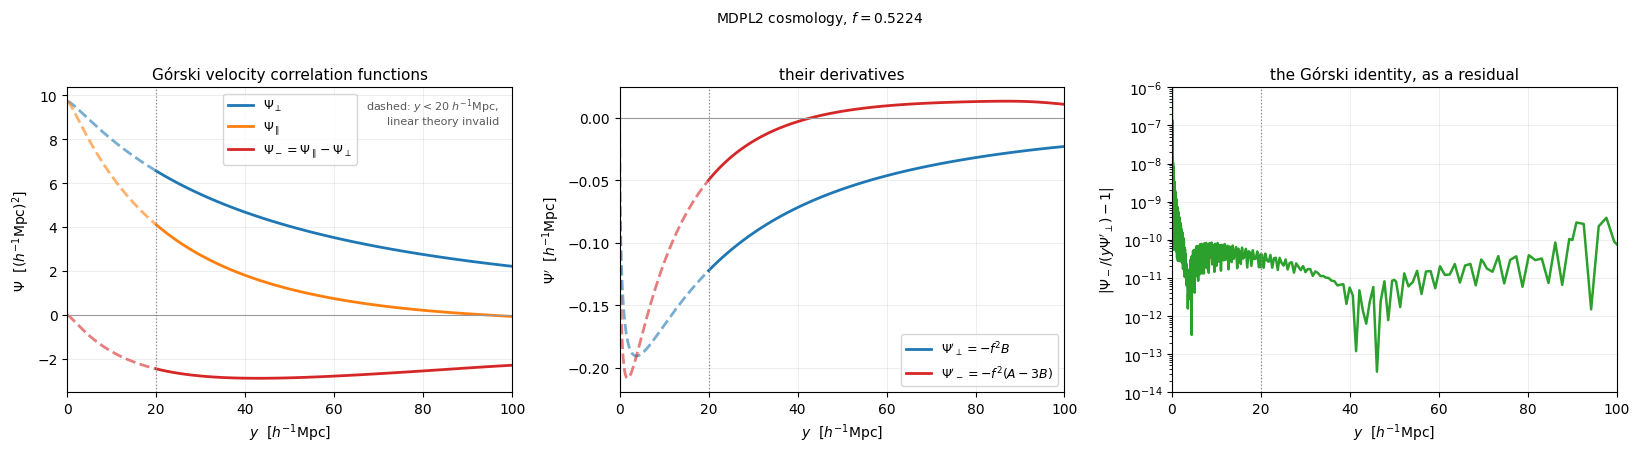

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.4))

PSI_PANELS = [
    ([(G_MDPL2.perp, r"$\Psi_\perp$", "C0"),
      (G_MDPL2.parallel, r"$\Psi_\parallel$", "C1"),
      (G_MDPL2.minus, r"$\Psi_-=\Psi_\parallel-\Psi_\perp$", "C3")],
     r"$\Psi$  [$(h^{-1}\mathrm{Mpc})^2$]",
     "Górski velocity correlation functions"),
    ([(G_MDPL2.perp_prime, r"$\Psi'_\perp=-f^2B$", "C0"),
      (G_MDPL2.minus_prime, r"$\Psi'_-=-f^2(A-3B)$", "C3")],
     r"$\Psi'$  [$h^{-1}$Mpc]",
     "their derivatives"),
]

for ax, (curves, ylabel, title) in zip(axes, PSI_PANELS):
    for values, label, colour in curves:
        ax.plot(y[above], values[above], color=colour, lw=2.0, label=label)
        ax.plot(y[below], values[below], color=colour, lw=2.0, ls="--", alpha=0.6)
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontsize=11)
    ax.axhline(0.0, color="0.6", lw=0.8)
    ax.legend(fontsize=9)

# Third panel: the Gorski identity as a RESIDUAL. Overplotting Psi_- on y Psi'_perp
# would just draw one curve twice; what is worth seeing is how close to zero the
# difference is, and that it is FFTLog noise rather than structure.
axes[2].semilogy(y, np.abs(residual), color="C2", lw=1.8)
axes[2].set_ylabel(r"$|\Psi_-/(y\Psi'_\perp)-1|$")
axes[2].set_title("the Górski identity, as a residual", fontsize=11)
axes[2].set_ylim(1e-14, 1e-6)

for ax in axes:
    ax.set_xlabel(r"$y$  [$h^{-1}$Mpc]")
    ax.axvline(LINEAR_FLOOR, color="0.55", lw=0.9, ls=":")
    ax.set_xlim(X_MIN_PLOT, X_MAX_PLOT)
    ax.grid(alpha=0.25, lw=0.6)

axes[0].text(0.97, 0.97, "dashed: $y<20\\ h^{-1}$Mpc,\nlinear theory invalid",
             transform=axes[0].transAxes, fontsize=8, color="0.35", ha="right", va="top")
fig.suptitle(f"MDPL2 cosmology, $f={F_MDPL2:.4f}$", fontsize=10, y=1.02)
fig.tight_layout()
plt.show()

## 4. The first moment, and the exact $j_2$ cancellation

Real space (Nusser eq. 13, with $\langle\mu^2\rangle=1/3$), and redshift space
(eq. 17 **with the sign corrected**):

$$\langle\xi_{u\delta}\rangle_1=-\frac{b}{f}\left(\Psi'_\perp+\frac{\Psi'_-}{3}\right),
\qquad
\langle\xi^{s}_{u\delta}\rangle_1=-\frac{b}{f}\left(\Psi'_\perp+\frac{\Psi'_-}{3}\right)
-\frac35\Psi'_\perp-\frac15\Psi'_-$$

The extra piece is $\langle\xi_{wu}\rangle_1$ — a *velocity–velocity* correlation, hence
bias-free, which is why the boost comes out as $b\to b+3f/5$ rather than
$b(1+3f/5)$.

Substituting $\Psi'_\perp=-f^2B$ and $\Psi'_-=-f^2(A-3B)$, the coefficient of $B$ is

$$\frac{b}{f}+\frac35-3\left(\frac{b}{3f}+\frac15\right)=0\qquad\text{exactly, for any }b,f$$

leaving $j_1$ alone. `dipole.dipole_from_gorski` evaluates the un-cancelled left-hand side;
`dipole.xi_udelta_dipole` evaluates $\tfrac{f}{3}(b+\tfrac{3f}{5})A$. They must agree to
machine precision, and that agreement is a test with **no free parameters**.

In [8]:
print("j_2 cancellation: un-cancelled (Psi'_perp, Psi'_-) vs cancelled (A alone).\n")
print(f"  {'f':>7}{'b':>7}{'real: max frac dev':>22}{'redshift: max frac dev':>26}")
worst_cancel = 0.0
for f_scan in (0.2, 0.4, 0.6, 0.8, 1.0):
    functions = gorski.gorski_functions(y, K_MDPL2, PK_MDPL2, f_scan)
    for b_scan in (0.5, 1.0, 2.0):
        row = []
        for space in (dipole.SPACE_REAL, dipole.SPACE_REDSHIFT):
            cancelled = dipole.xi_udelta_dipole(
                y, K_MDPL2, PK_MDPL2, f=f_scan, b=b_scan, space=space,
                a_hubble=AH_MDPL2, shape_integral=A_MDPL2,
            )
            explicit = dipole.dipole_from_gorski(
                functions, b=b_scan, space=space, a_hubble=AH_MDPL2
            )
            row.append(float(np.max(np.abs(cancelled[positive] / explicit[positive] - 1.0))))
        worst_cancel = max(worst_cancel, max(row))
        print(f"  {f_scan:7.2f}{b_scan:7.2f}{row[0]:22.2e}{row[1]:26.2e}")

print(f"\n  worst over the sweep: {worst_cancel:.2e}  -- machine precision, for every (f, b).")

j_2 cancellation: un-cancelled (Psi'_perp, Psi'_-) vs cancelled (A alone).

        f      b    real: max frac dev    redshift: max frac dev
     0.20   0.50              5.55e-16                  4.44e-16
     0.20   1.00              5.55e-16                  4.44e-16
     0.20   2.00              5.55e-16                  4.44e-16
     0.40   0.50              5.55e-16                  5.55e-16
     0.40   1.00              5.55e-16                  4.44e-16
     0.40   2.00              5.55e-16                  4.44e-16
     0.60   0.50              3.33e-16                  4.44e-16
     0.60   1.00              3.33e-16                  4.44e-16
     0.60   2.00              3.33e-16                  4.44e-16
     0.80   0.50              5.55e-16                  4.44e-16
     0.80   1.00              5.55e-16                  5.55e-16
     0.80   2.00              5.55e-16                  4.44e-16
     1.00   0.50              4.44e-16                  4.44e-16
     1.00   1.

### The negative control: what the *printed* eq. (17) does

"The cancellation works" only shows the algebra was done consistently. The claim that the
sign is the **right** one needs the counterfactual. With the printed $+1/(3f)$ a residual
$-\tfrac{2b}{3f}\Psi'_-$ survives; because $\Psi'_-$ and $A$ have different shapes, the
redshift/real ratio stops being constant in $y$ — which is the *observable* symptom, and
exactly the "flat measured/theory ratio through the nonlinear regime is a bug signature"
warning read in reverse.

In [9]:
f_ctl, b_ctl = F_MDPL2, 1.0
functions_ctl = gorski.gorski_functions(y, K_MDPL2, PK_MDPL2, f_ctl)

real = dipole.dipole_from_gorski(functions_ctl, b=b_ctl, space=dipole.SPACE_REAL, a_hubble=AH_MDPL2)
corrected = dipole.dipole_from_gorski(functions_ctl, b=b_ctl, space=dipole.SPACE_REDSHIFT, a_hubble=AH_MDPL2)
# Eq. (17) exactly as printed: +b/(3f) where the corrected version has -b/(3f).
printed = AH_MDPL2 * (
    -(3.0 / 5.0 + b_ctl / f_ctl) * functions_ctl.perp_prime
    - (1.0 / 5.0 - b_ctl / (3.0 * f_ctl)) * functions_ctl.minus_prime
)

print(f"  {'y':>6}{'real':>12}{'corrected':>12}{'printed':>12}"
      f"{'corr/real':>12}{'printed/real':>14}")
for y_i in (20.0, 30.0, 50.0, 70.0, 90.0):
    j = int(np.argmin(np.abs(y - y_i)))
    print(f"  {y[j]:6.1f}{real[j]:12.4f}{corrected[j]:12.4f}{printed[j]:12.4f}"
          f"{corrected[j] / real[j]:12.6f}{printed[j] / real[j]:14.6f}")

fit_range = (y >= LINEAR_FLOOR)
print(f"\n  corrected ratio over y >= {LINEAR_FLOOR:.0f}: spread {np.ptp(corrected[fit_range] / real[fit_range]):.2e}"
      f"  (target 1 + 3f/5 = {dipole.dipole_boost(b_ctl, f_ctl):.6f})")
print(f"  printed   ratio over y >= {LINEAR_FLOOR:.0f}: spread {np.ptp(printed[fit_range] / real[fit_range]):.2e}"
      "   <- scale-DEPENDENT, the j_2 contamination")

       y        real   corrected     printed   corr/real  printed/real
    20.0     26.5942     34.9301     28.5764    1.313449      1.074536
    30.0     18.8731     24.7888     22.4031    1.313449      1.187040
    50.0     10.5851     13.9030     14.5864    1.313449      1.378013
    70.0      6.5252      8.5705     10.1024    1.313449      1.548224
    90.0      4.2653      5.6023      7.3067    1.313449      1.713065

  corrected ratio over y >= 20: spread 6.66e-16  (target 1 + 3f/5 = 1.313449)
  printed   ratio over y >= 20: spread 9.79e-01   <- scale-DEPENDENT, the j_2 contamination


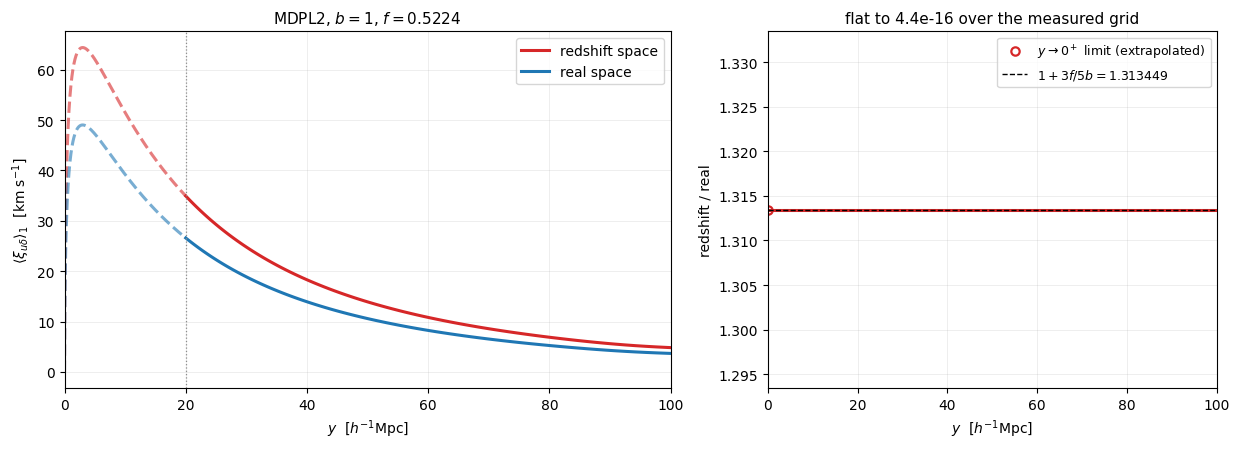

redshift/real ratio: min 1.313448947659  max 1.313448947659  spread 4.44e-16   (over y > 0, the measured nodes)
extrapolated y -> 0+ limit: 1.313448947659   vs analytic 1+3f/5b 1.313448947659   -> |diff| 0.00e+00
The plotted point at y = 0 is that extrapolation, not the analytic value, and not
0: the dipole vanishes at zero separation but the RATIO of the two dipoles does not.


In [10]:
ZETA_REAL = dipole.xi_udelta_dipole(y, K_MDPL2, PK_MDPL2, f=F_MDPL2, b=B_FID,
                                    space=dipole.SPACE_REAL, a_hubble=AH_MDPL2,
                                    shape_integral=A_MDPL2)
ZETA_RSD = dipole.xi_udelta_dipole(y, K_MDPL2, PK_MDPL2, f=F_MDPL2, b=B_FID,
                                   space=dipole.SPACE_REDSHIFT, a_hubble=AH_MDPL2,
                                   shape_integral=A_MDPL2)

fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(12.5, 4.6),
                                 gridspec_kw={"width_ratios": [1.35, 1.0]})

for values, label, colour in [(ZETA_RSD, "redshift space", "C3"), (ZETA_REAL, "real space", "C0")]:
    ax_l.plot(y[above], values[above], color=colour, lw=2.2, label=label)
    ax_l.plot(y[below], values[below], color=colour, lw=2.2, ls="--", alpha=0.6)
ax_l.set_xlabel(r"$y$  [$h^{-1}$Mpc]")
ax_l.set_ylabel(r"$\langle\xi_{u\delta}\rangle_1$  [km s$^{-1}$]")
ax_l.set_title(rf"MDPL2, $b={B_FID:g}$, $f={F_MDPL2:.4f}$", fontsize=11)
ax_l.set_xlim(X_MIN_PLOT, X_MAX_PLOT)
ax_l.axvline(LINEAR_FLOOR, color="0.55", lw=0.9, ls=":")
ax_l.grid(alpha=0.25, lw=0.6)
ax_l.legend()

ratio = ZETA_RSD[positive] / ZETA_REAL[positive]
x_ratio, ratio_to_zero = ratio_to_origin(ratio)
ax_r.plot(x_ratio, ratio_to_zero, color="C3", lw=2.2)
ax_r.plot([0.0], ratio_to_zero[:1], "o", ms=6, mfc="none", mec="C3", mew=1.6,
          label=r"$y\to0^+$ limit (extrapolated)")
ax_r.axhline(dipole.dipole_boost(B_FID, F_MDPL2), color="k", lw=1.0, ls="--",
             label=rf"$1+3f/5b={dipole.dipole_boost(B_FID, F_MDPL2):.6f}$")
ax_r.set_xlabel(r"$y$  [$h^{-1}$Mpc]")
ax_r.set_ylabel("redshift / real")
ax_r.set_title(f"flat to {np.ptp(ratio):.1e} over the measured grid", fontsize=11)
ax_r.set_xlim(X_MIN_PLOT, X_MAX_PLOT)
ax_r.set_ylim(dipole.dipole_boost(B_FID, F_MDPL2) - 0.02,
              dipole.dipole_boost(B_FID, F_MDPL2) + 0.02)
ax_r.grid(alpha=0.25, lw=0.6)
ax_r.legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"redshift/real ratio: min {ratio.min():.12f}  max {ratio.max():.12f}  "
      f"spread {np.ptp(ratio):.2e}   (over y > 0, the measured nodes)")
print(f"extrapolated y -> 0+ limit: {ratio_to_zero[0]:.12f}   vs analytic 1+3f/5b "
      f"{dipole.dipole_boost(B_FID, F_MDPL2):.12f}   -> "
      f"|diff| {abs(ratio_to_zero[0] - dipole.dipole_boost(B_FID, F_MDPL2)):.2e}")
print("The plotted point at y = 0 is that extrapolation, not the analytic value, and not")
print("0: the dipole vanishes at zero separation but the RATIO of the two dipoles does not.")

## 5. Dependence on $f$, $\sigma_8$ and $b$

Writing $P=\sigma_8^2\hat P$ and $A=\sigma_8^2\hat A$,

$$\boxed{\;\langle\xi^{s}_{u\delta_g}\rangle_1(y)=\frac{aH}{3}
\left[(f\sigma_8)(b\sigma_8)+\frac35(f\sigma_8)^2\right]\hat A(y)\;}$$

which is Nusser eq. (35) with $\sigma_8^g\equiv b\sigma_8$. The consequences worth
asserting:

| piece | scaling | carries $b$? |
|---|---|---|
| real-space dipole | $f\sigma_8\cdot\sigma_8^g = bf\sigma_8^2$ | yes |
| RSD ($\xi_{wu}$) addition | $(f\sigma_8)^2$ | no |
| octupole $\ell=3$ | $(f\sigma_8)^2$ | no |
| $2\xi_{uu}/\tilde r$ ($\ell=0,2$ only) | $(f\sigma_8)^2$ | no |

The **shape** $\hat A(y)$ is independent of all three. Only the prefactor moves — which is
what makes the collapse test below meaningful, and what makes $\langle\xi\rangle_1$ alone
unable to separate $b$ from $f$ from $\sigma_8$.

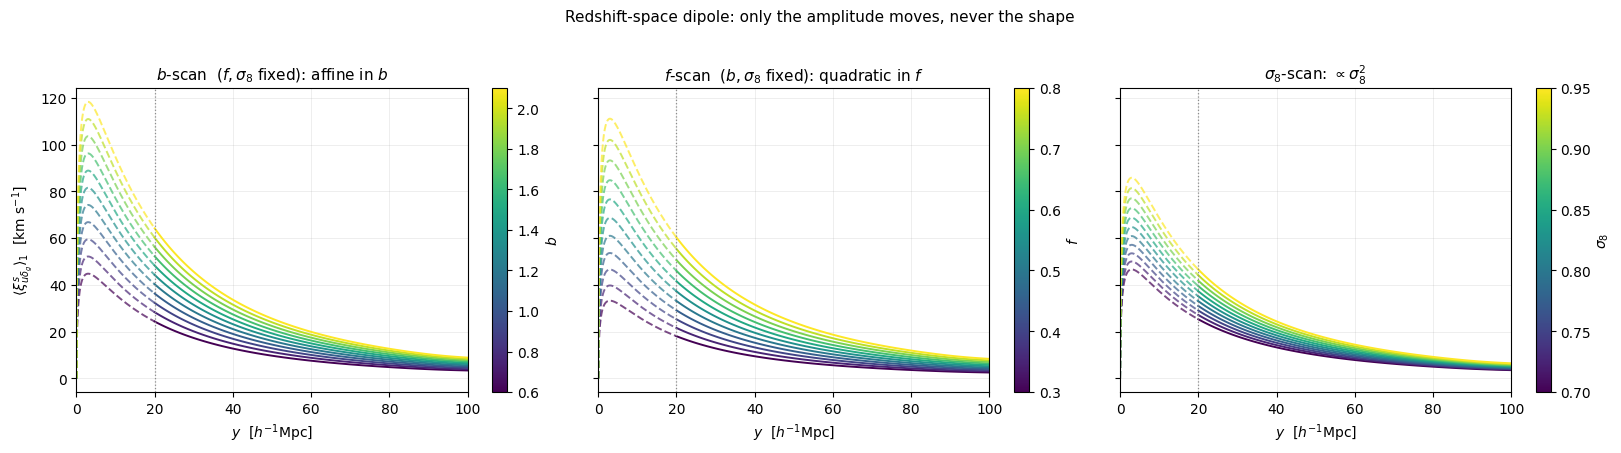

In [11]:
def dipole_curve(f, b=B_FID, sigma8=None, space=dipole.SPACE_REDSHIFT):
    """zeta_1(y) in km/s from the CACHED A(y), rescaled for sigma8.

    P is linear in A_s and sigma8**2 is linear in P, so multiplying the cached A by
    (sigma8/sigma8_fid)**2 is EXACTLY re-running CAMB at the new normalization. Nothing
    here recomputes a transform -- that is the point: the collapse test below would be
    tautological if the shape were regenerated per parameter.
    """
    scale = 1.0 if sigma8 is None else (sigma8 / COSMO_MDPL2.sigma8) ** 2
    return dipole.xi_udelta_dipole(
        y, K_MDPL2, PK_MDPL2, f=f, b=b, space=space,
        a_hubble=AH_MDPL2, shape_integral=A_MDPL2 * scale,
    )


CMAP = "viridis"
N_SCAN = 11


def draw_scan(ax, values, curves, cbar_label, x=None):
    """`x` defaults to the full grid; the beta panel passes its own abscissa,
    because its curves are ratios -- 0/0 at the origin, so their value there comes
    from `ratio_to_origin` rather than from an evaluation."""
    x = y if x is None else x
    hi, lo = x >= LINEAR_FLOOR, x <= LINEAR_FLOOR
    norm = Normalize(vmin=float(np.min(values)), vmax=float(np.max(values)))
    mappable = ScalarMappable(norm=norm, cmap=CMAP)
    for value, curve in zip(values, curves):
        colour = mappable.to_rgba(value)
        ax.plot(x[hi], curve[hi], color=colour, lw=1.4)
        ax.plot(x[lo], curve[lo], color=colour, lw=1.4, ls="--", alpha=0.7)
    ax.set_xlabel(r"$y$  [$h^{-1}$Mpc]")
    ax.set_xlim(X_MIN_PLOT, X_MAX_PLOT)
    ax.axvline(LINEAR_FLOOR, color="0.55", lw=0.9, ls=":")
    ax.grid(alpha=0.25, lw=0.6)
    plt.colorbar(mappable, ax=ax, label=cbar_label)
    return mappable


B_SCAN = np.linspace(0.6, 2.1, N_SCAN)
F_SCAN = np.linspace(0.30, 0.80, N_SCAN)
S8_SCAN = np.linspace(0.70, 0.95, N_SCAN)

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.4), sharey=True)
draw_scan(axes[0], B_SCAN, [dipole_curve(F_MDPL2, b=b_i) for b_i in B_SCAN], r"$b$")
draw_scan(axes[1], F_SCAN, [dipole_curve(f_i) for f_i in F_SCAN], r"$f$")
draw_scan(axes[2], S8_SCAN, [dipole_curve(F_MDPL2, sigma8=s_i) for s_i in S8_SCAN], r"$\sigma_8$")
axes[0].set_ylabel(r"$\langle\xi^s_{u\delta_g}\rangle_1$  [km s$^{-1}$]")
for ax, title in zip(axes, [
    r"$b$-scan  ($f,\sigma_8$ fixed): affine in $b$",
    r"$f$-scan  ($b,\sigma_8$ fixed): quadratic in $f$",
    r"$\sigma_8$-scan: $\propto\sigma_8^2$",
]):
    ax.set_title(title, fontsize=11)
fig.suptitle("Redshift-space dipole: only the amplitude moves, never the shape", fontsize=11, y=1.02)
fig.tight_layout()
plt.show()

In [12]:
print("Quantitative checks on the three scans -- printed, not eyeballed.\n")

# 1. real space is strictly proportional to b; redshift space is AFFINE in b.
real_one = dipole_curve(F_MDPL2, b=1.0, space=dipole.SPACE_REAL)
real_two = dipole_curve(F_MDPL2, b=2.0, space=dipole.SPACE_REAL)
print(f"1. real space, zeta(b=2) / (2 zeta(b=1)) - 1 : "
      f"max {np.max(np.abs(real_two[positive] / (2.0 * real_one[positive]) - 1.0)):.2e}"
      "   -> strictly proportional to b")

intercept = dipole_curve(F_MDPL2, b=0.0, space=dipole.SPACE_REDSHIFT)
expected_intercept = AH_MDPL2 * (F_MDPL2 / 3.0) * (3.0 * F_MDPL2 / 5.0) * A_MDPL2
print(f"   redshift space, b -> 0 intercept vs (aH f/3)(3f/5)A : "
      f"max {np.max(np.abs(intercept[positive] / expected_intercept[positive] - 1.0)):.2e}"
      "   -> affine, not proportional")

# 2. the boost depends on f and b only through beta.
print("\n2. the boost depends on (f, b) only through beta = f/b:")
print(f"   {'f':>6}{'b':>6}{'beta':>8}{'boost':>12}")
for f_i, b_i in [(0.5, 1.0), (1.0, 2.0), (0.25, 0.5), (0.53, 1.0), (0.795, 1.5)]:
    print(f"   {f_i:6.3f}{b_i:6.2f}{f_i / b_i:8.3f}{dipole.dipole_boost(b_i, f_i):12.8f}")

# 3. the collapse test.
print("\n3. collapse: divide by (aH/3)[(f s8)(b s8) + (3/5)(f s8)^2] and every curve is one curve.")
reference = None
worst_collapse = 0.0
n_curves = 0
for f_i in (0.30, 0.45, F_MDPL2, 0.70, 0.90):
    for b_i in (0.6, 1.0, 1.6, 2.4):
        for s8_i in (0.70, COSMO_MDPL2.sigma8, 0.95):
            scale = (s8_i / COSMO_MDPL2.sigma8) ** 2
            curve = dipole_curve(f_i, b=b_i, sigma8=s8_i)
            amplitude = dipole.dipole_amplitude(
                f_i, b_i, dipole.SPACE_REDSHIFT, a_hubble=AH_MDPL2
            ) * scale
            shape = curve / amplitude
            reference = shape if reference is None else reference
            worst_collapse = max(
                worst_collapse,
                float(np.max(np.abs(shape[positive] / reference[positive] - 1.0))),
            )
            n_curves += 1
print(f"   {n_curves} curves, max deviation from the common shape: {worst_collapse:.2e}")
print("   (A_hat is CACHED and shared, so this tests the factorization, not the transform.)")

Quantitative checks on the three scans -- printed, not eyeballed.

1. real space, zeta(b=2) / (2 zeta(b=1)) - 1 : max 0.00e+00   -> strictly proportional to b
   redshift space, b -> 0 intercept vs (aH f/3)(3f/5)A : max 0.00e+00   -> affine, not proportional

2. the boost depends on (f, b) only through beta = f/b:
        f     b    beta       boost
    0.500  1.00   0.500  1.30000000
    1.000  2.00   0.500  1.30000000
    0.250  0.50   0.500  1.30000000
    0.530  1.00   0.530  1.31800000
    0.795  1.50   0.530  1.31800000

3. collapse: divide by (aH/3)[(f s8)(b s8) + (3/5)(f s8)^2] and every curve is one curve.
   60 curves, max deviation from the common shape: 4.44e-16
   (A_hat is CACHED and shared, so this tests the factorization, not the transform.)


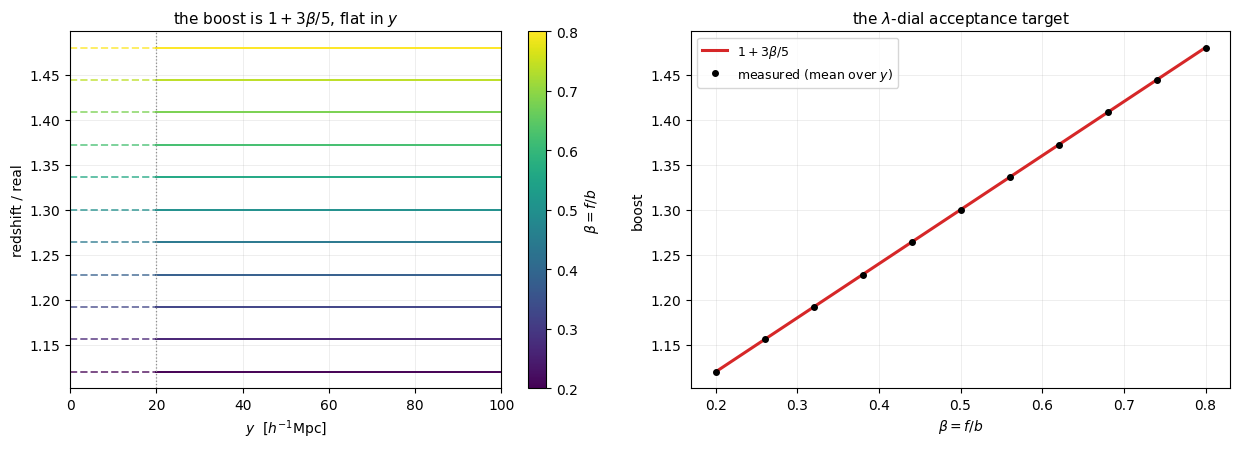

max |measured boost / (1+3beta/5) - 1| over the scan: 3.33e-16
the same boost at sigma8 = 0.70 / 0.8228 / 0.95: 1.313448947659 / 1.313448947659 / 1.313448947659
-> the boost genuinely does not know about sigma8; it cancels in the ratio.


In [13]:
# The beta panel: fix f*sigma8, vary beta, and watch only the RSD term move.
BETA_SCAN = np.linspace(0.20, 0.80, N_SCAN)

fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(12.5, 4.6))

curves_beta = []
for beta in BETA_SCAN:
    b_beta = F_MDPL2 / beta
    curves_beta.append(dipole_curve(F_MDPL2, b=b_beta)[positive]
                       / dipole_curve(F_MDPL2, b=b_beta, space=dipole.SPACE_REAL)[positive])
x_beta, _ = ratio_to_origin(curves_beta[0])
draw_scan(ax_l, BETA_SCAN, [ratio_to_origin(c)[1] for c in curves_beta],
          r"$\beta=f/b$", x=x_beta)
ax_l.set_ylabel("redshift / real")
ax_l.set_title(r"the boost is $1+3\beta/5$, flat in $y$", fontsize=11)

ax_r.plot(BETA_SCAN, [1.0 + 3.0 * beta / 5.0 for beta in BETA_SCAN], color="C3", lw=2.2,
          label=r"$1+3\beta/5$")
measured = [float(np.mean(c)) for c in curves_beta]   # measured nodes only, no origin point
ax_r.plot(BETA_SCAN, measured, "o", ms=4, color="k", label="measured (mean over $y$)")
ax_r.set_xlabel(r"$\beta=f/b$")
ax_r.set_ylabel("boost")
ax_r.set_title("the $\\lambda$-dial acceptance target", fontsize=11)
ax_r.grid(alpha=0.25, lw=0.6)
ax_r.legend(fontsize=9)
fig.tight_layout()
plt.show()

print(f"max |measured boost / (1+3beta/5) - 1| over the scan: "
      f"{max(abs(m / (1.0 + 3.0 * b_i / 5.0) - 1.0) for m, b_i in zip(measured, BETA_SCAN)):.2e}")
sigma8_probe = [
    float(np.mean(dipole_curve(F_MDPL2, b=1.0, sigma8=s8)[positive]
                  / dipole_curve(F_MDPL2, b=1.0, sigma8=s8, space=dipole.SPACE_REAL)[positive]))
    for s8 in (0.70, 0.8228, 0.95)
]
print(f"the same boost at sigma8 = 0.70 / 0.8228 / 0.95: "
      f"{sigma8_probe[0]:.12f} / {sigma8_probe[1]:.12f} / {sigma8_probe[2]:.12f}")
print("-> the boost genuinely does not know about sigma8; it cancels in the ratio.")

## 6. Conventions and signs — the two factors that are easy to lose

There are two distinct conversions between what this notebook computes and what the
pipeline measures, and conflating them is a factor of $\pm3$ waiting to happen.

- **Normalisation** ($\times3$): Nusser's $\tfrac12\int\xi L_1 d\mu$ against the standard
  $\tfrac32\int\xi L_1 d\mu$.
- **Orientation** ($\times-1$): velocity-centred against group-centred.

A point worth stating explicitly, because §0 of the implementation note can be read the
other way: **this project's estimator already uses Nusser's normalisation.** The
`normalize_stacked_dipole` denominator carries the $\langle\mu^2\rangle=1/3$ of a uniform
shell and no $(2\ell+1)$, which is why `pipeline.galaxy_bias.zeta_one_linear_prediction`
matches `xi_udelta_dipole(..., convention=CONVENTION_NUSSER)` exactly, with no 3 anywhere.
So the number to overlay on a measured $\hat\zeta_1$ is the **Nusser-normalised** one; the
$\xi_{Tu,1}=-3\,\zeta^V_{\rm Nusser}$ of the note is the relation to the *standard*
convention, and applies only if you deliberately move into it.

In [14]:
shared = dict(f=F_MDPL2, b=1.3, space=dipole.SPACE_REDSHIFT, a_hubble=AH_MDPL2,
              shape_integral=A_MDPL2)
nusser_norm = dipole.xi_udelta_dipole(y, K_MDPL2, PK_MDPL2, **shared)
standard_norm = dipole.xi_udelta_dipole(y, K_MDPL2, PK_MDPL2,
                                        convention=dipole.CONVENTION_STANDARD, **shared)

print("1. Normalisation")
print("   standard / nusser: max |ratio - 3| = "
      f"{np.max(np.abs(standard_norm[positive] / nusser_norm[positive] - 3.0)):.2e}")
print(f"   convention_factor(standard, ell=1) = {dipole.convention_factor(dipole.CONVENTION_STANDARD, 1)}, "
      f"ell=3 -> {dipole.convention_factor(dipole.CONVENTION_STANDARD, 3)}")

print("\n2. Orientation (hard rule 2: the group-centered dipole is NEGATIVE for infall)")
group_centered = conventions.nusser_multipole_sign(1) * nusser_norm
# The sign statement is about y > 0. At y = 0 the dipole is EXACTLY zero -- no
# separation, no direction, no dipole -- so sign() is 0 there and the strict test
# has to exclude it or it fails on a point where there is nothing to have a sign.
print(f"   at y = 0 exactly:            {nusser_norm[0]:+.4e}  (zero separation -> zero dipole)")
print(f"   velocity-centered (Nusser)  min over y > 0 = {nusser_norm[positive].min():+.4f}"
      f"  -> all positive: {bool(np.all(nusser_norm[positive] > 0))}")
print(f"   group-centered  xi_Tu,1     max over y > 0 = {group_centered[positive].max():+.4f}"
      f"  -> sign matches conventions.INFALL_DIPOLE_SIGN "
      f"({conventions.INFALL_DIPOLE_SIGN}): "
      f"{bool(np.all(np.sign(group_centered[positive]) == conventions.INFALL_DIPOLE_SIGN))}")

print("\n3. Agreement with the production overlay, pipeline.galaxy_bias.zeta_one_linear_prediction")
production = gb.zeta_one_linear_prediction(y, b=1.3, cosmology=COSMO_MDPL2, z=Z,
                                           power_spectrum=(K_MDPL2, PK_MDPL2))
theory_real = dipole.xi_udelta_dipole(y, K_MDPL2, PK_MDPL2, f=F_MDPL2, b=1.3,
                                      space=dipole.SPACE_REAL, a_hubble=AH_MDPL2,
                                      shape_integral=A_MDPL2)
print(f"   max |theory(real, nusser) / production - 1| = "
      f"{np.max(np.abs(theory_real[positive] / production[positive] - 1.0)):.2e}")
print("   -> the same number. dvcorr.theory does not introduce a second normalisation.")

1. Normalisation
   standard / nusser: max |ratio - 3| = 4.44e-16
   convention_factor(standard, ell=1) = 3.0, ell=3 -> 7.0

2. Orientation (hard rule 2: the group-centered dipole is NEGATIVE for infall)
   at y = 0 exactly:            +0.0000e+00  (zero separation -> zero dipole)
   velocity-centered (Nusser)  min over y > 0 = +2.7503  -> all positive: True
   group-centered  xi_Tu,1     max over y > 0 = -2.7503  -> sign matches conventions.INFALL_DIPOLE_SIGN (-1): True

3. Agreement with the production overlay, pipeline.galaxy_bias.zeta_one_linear_prediction
   max |theory(real, nusser) / production - 1| = 2.22e-16
   -> the same number. dvcorr.theory does not introduce a second normalisation.


## 7. Reproducing Nusser's Figure 1

Five curves, Planck cosmology, $b=1$. Nusser's own axes are $y\in[0,60]\ {\rm km\,s^{-1}}$
and $x\in[10,90]\ h^{-1}$Mpc; the panel below is drawn on this notebook's shared
$0$–$100\ h^{-1}$Mpc range instead, with his window shaded, so the curves can be read
against the other figures. Widening the left edge exposes the turnover below
$y\sim4\,h^{-1}$Mpc — deep inside the region where linear theory is meaningless, and the
reason the "$\sim$60 km/s peak" of the checklist below is a read of his plot's left edge
rather than an actual maximum:

| curve | style | quantity |
|---|---|---|
| 1 | black solid | $\langle\xi^s_{u\delta}\rangle_1$, DOL ($r=\infty$) |
| 2 | black dashed | $\langle\xi_{u\delta}\rangle_1$, real space, DOL |
| 3 | blue solid | $\langle\xi^s_{u\delta}\rangle_1$ at finite $r=50\,h^{-1}$Mpc |
| 4 | blue dash-dot | $\langle 2\xi_{uu}/\tilde r\rangle_0$ |
| 5 | blue dotted | $\langle 2\xi_{uu}/\tilde r\rangle_1$ at $r=50\,h^{-1}$Mpc |

Curves 1–2 come straight from §4. Curves 3–5 need exact geometry:

$$\tilde r=\sqrt{r^2+y^2+2ry\mu},\qquad \nu=\frac{r+y\mu}{\tilde r},\qquad
\tilde\mu=\frac{r\mu+y}{\tilde r}$$

### 7.1 Validating the geometry first

Two facts make this checkable without reference to a plot.

**Real space is distance-independent.** Nusser eq. (13) contains no $\tilde r$, $\nu$ or
$\tilde\mu$, so the real-space dipole equals its DOL value at *any* observer distance.
Every finite-distance effect on this statistic is a redshift-space effect.

**Curve 5 must vanish in the DOL.** $\xi_{uu}$ is even in $\mu$ when $\nu\to1$ and
$\tilde\mu\to\mu$, so its dipole is a pure finite-distance effect — the Kaiser rocket is
absent from the dipole by construction. A non-zero curve 5 at $y\ll r$ means the geometry
is wrong, not that the physics is interesting. And curves 3 and 5 must converge to their
DOL limits as $r^{-2}$; agreement at one distance could be two wrong formulae colliding, a
clean power law over four decades cannot.

In [15]:
G_NUSSER = gorski.gorski_functions(y, K_NUSSER, PK_NUSSER, F_NUSSER)
R_OBS = 50.0  # h^-1 Mpc, Nusser's finite-distance curves

print("a) DOL cosines: nu -> 1, mu_tilde -> mu")
mu_nodes, _ = wide_angle.gauss_legendre_nodes(65)
far_geometry = wide_angle.wide_angle_geometry(np.array([1.0]), mu_nodes, r_obs=1e8)
print(f"   max |nu - 1|        = {np.max(np.abs(far_geometry.nu - 1.0)):.2e}")
print(f"   max |mu_tilde - mu| = {np.max(np.abs(far_geometry.mu_tilde - mu_nodes)):.2e}")

print("\nb) the real-space dipole does not depend on the observer distance")
real_dol = dipole.xi_udelta_dipole(y, K_NUSSER, PK_NUSSER, f=F_NUSSER, b=B_FID,
                                   space=dipole.SPACE_REAL, a_hubble=AH_NUSSER,
                                   shape_integral=A_NUSSER)
for r_test in (30.0, 50.0, 5000.0):
    near = wide_angle.xi_udelta_wide_angle_moment(y, r_test, G_NUSSER, 1, b=B_FID,
                                                  space=dipole.SPACE_REAL, a_hubble=AH_NUSSER)
    print(f"   r_obs = {r_test:7.0f}:  max |exact / DOL - 1| = "
          f"{np.max(np.abs(near[positive] / real_dol[positive] - 1.0)):.2e}")

print("\nc) the DOL monopole of 2 xi_uu / r_tilde reduces to Nusser eq. (16)")
r_far = 1e5
monopole_far = wide_angle.xi_uu_over_r_tilde_moment(y, r_far, G_NUSSER, 0)
eq16 = 2.0 * (G_NUSSER.perp + G_NUSSER.minus / 3.0) / r_far
print(f"   max |<2 xi_uu/r~>_0 / [2(Psi_perp + Psi_-/3)/r] - 1| = "
      f"{np.max(np.abs(monopole_far / eq16 - 1.0)):.2e}")

print("\nd) convergence to the DOL: both wide-angle quantities must fall as r_obs^-2")
rsd_dol = dipole.xi_udelta_dipole(y, K_NUSSER, PK_NUSSER, f=F_NUSSER, b=B_FID,
                                  space=dipole.SPACE_REDSHIFT, a_hubble=AH_NUSSER,
                                  shape_integral=A_NUSSER)
print(f"   {'r_obs':>9}{'max |curve3/curve1 - 1|':>26}{'max |curve5|  [km/s]':>24}")
for r_test in (50.0, 500.0, 5000.0, 50000.0):
    c3 = wide_angle.xi_udelta_wide_angle_moment(y, r_test, G_NUSSER, 1, b=B_FID,
                                                space=dipole.SPACE_REDSHIFT, a_hubble=AH_NUSSER)
    c5 = wide_angle.xi_uu_over_r_tilde_moment(y, r_test, G_NUSSER, 1, a_hubble=AH_NUSSER)
    print(f"   {r_test:9.0f}"
          f"{np.max(np.abs(c3[positive] / rsd_dol[positive] - 1.0)):26.3e}"
          f"{np.max(np.abs(c5)):24.3e}")
print("   each factor of 10 in r_obs buys a factor of ~100 -> the geometry is right.")

a) DOL cosines: nu -> 1, mu_tilde -> mu
   max |nu - 1|        = 2.22e-16
   max |mu_tilde - mu| = 1.00e-08

b) the real-space dipole does not depend on the observer distance
   r_obs =      30:  max |exact / DOL - 1| = 1.49e-14
   r_obs =      50:  max |exact / DOL - 1| = 1.49e-14
   r_obs =    5000:  max |exact / DOL - 1| = 1.49e-14

c) the DOL monopole of 2 xi_uu / r_tilde reduces to Nusser eq. (16)


   max |<2 xi_uu/r~>_0 / [2(Psi_perp + Psi_-/3)/r] - 1| = 2.66e-07

d) convergence to the DOL: both wide-angle quantities must fall as r_obs^-2
       r_obs   max |curve3/curve1 - 1|    max |curve5|  [km/s]


          50                 1.070e-01               3.236e+00
         500                 4.875e-03               4.718e-02


        5000                 4.982e-05               4.750e-04


       50000                 4.983e-07               4.750e-06
   each factor of 10 in r_obs buys a factor of ~100 -> the geometry is right.


In [16]:
# The five curves, on Nusser's own axes.
curve1 = rsd_dol
curve2 = real_dol
curve3 = wide_angle.xi_udelta_wide_angle_moment(y, R_OBS, G_NUSSER, 1, b=B_FID,
                                                space=dipole.SPACE_REDSHIFT, a_hubble=AH_NUSSER)
curve4 = wide_angle.xi_uu_over_r_tilde_moment(y, R_OBS, G_NUSSER, 0, a_hubble=AH_NUSSER)
curve5 = wide_angle.xi_uu_over_r_tilde_moment(y, R_OBS, G_NUSSER, 1, a_hubble=AH_NUSSER)

print(f"Nusser cosmology, b = {B_FID:g}, f = {F_NUSSER:.4f}, r_obs = {R_OBS:.0f} h^-1 Mpc  [km/s]\n")
print(f"  {'y':>6}{'1: RSD DOL':>13}{'2: real DOL':>13}{'3: RSD r=50':>13}"
      f"{'4: rocket_0':>13}{'5: rocket_1':>13}{'1/2':>9}")
for y_i in (10.0, 15.0, 20.0, 30.0, 50.0, 70.0, 90.0):
    j = int(np.argmin(np.abs(y - y_i)))
    print(f"  {y[j]:6.1f}{curve1[j]:13.3f}{curve2[j]:13.3f}{curve3[j]:13.3f}"
          f"{curve4[j]:13.3f}{curve5[j]:13.3f}{curve1[j] / curve2[j]:9.5f}")

Nusser cosmology, b = 1, f = 0.5251, r_obs = 50 h^-1 Mpc  [km/s]

       y   1: RSD DOL  2: real DOL  3: RSD r=50  4: rocket_0  5: rocket_1      1/2
    10.0       52.672       40.053       54.404       29.520       -2.009  1.31507
    15.0       42.952       32.662       45.042       25.369       -2.596  1.31507
    20.0       35.422       26.936       37.662       21.860       -2.974  1.31507
    30.0       24.994       19.006       27.102       16.251       -3.235  1.31507
    50.0       13.907       10.575       14.312        8.040       -1.920  1.31507
    70.0        8.523        6.481        7.856        3.548       -0.626  1.31507
    90.0        5.544        4.216        4.957        1.867       -0.380  1.31507


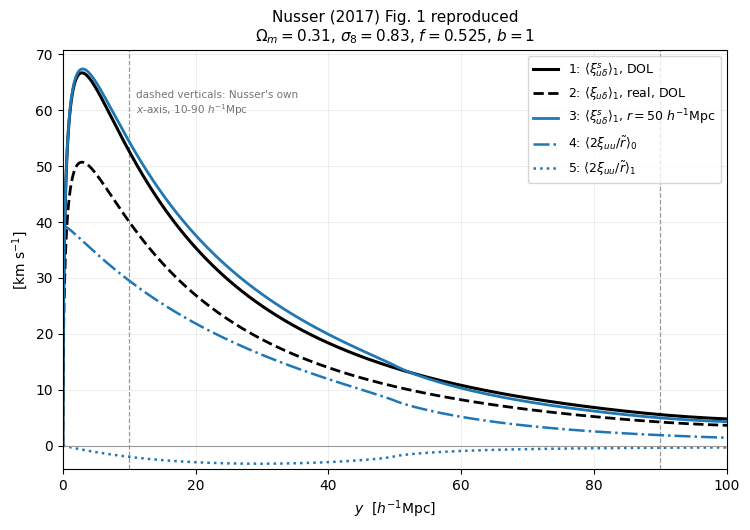

In [17]:
fig, ax = plt.subplots(figsize=(7.6, 5.4))

ax.plot(y, curve1, color="k", lw=2.2, label=r"1: $\langle\xi^s_{u\delta}\rangle_1$, DOL")
ax.plot(y, curve2, color="k", lw=2.0, ls="--", label=r"2: $\langle\xi_{u\delta}\rangle_1$, real, DOL")
ax.plot(y, curve3, color="C0", lw=2.0,
        label=rf"3: $\langle\xi^s_{{u\delta}}\rangle_1$, $r={R_OBS:.0f}\ h^{{-1}}$Mpc")
ax.plot(y, curve4, color="C0", lw=1.8, ls="-.", label=r"4: $\langle 2\xi_{uu}/\tilde r\rangle_0$")
ax.plot(y, curve5, color="C0", lw=1.8, ls=":", label=r"5: $\langle 2\xi_{uu}/\tilde r\rangle_1$")

ax.axhline(0.0, color="0.6", lw=0.8)
ax.set_xlim(X_MIN_PLOT, X_MAX_PLOT)
in_view = (y >= X_MIN_PLOT) & (y <= X_MAX_PLOT)
y_top = 1.05 * max(float(np.max(c[in_view])) for c in (curve1, curve2, curve3, curve4))
y_bottom = 1.30 * min(float(np.min(c[in_view])) for c in (curve1, curve2, curve3, curve4, curve5))
ax.set_ylim(y_bottom, y_top)
for edge in (10.0, 90.0):
    ax.axvline(edge, color="0.6", lw=0.9, ls="--", zorder=0)
ax.text(11.0, 0.90 * y_top, "dashed verticals: Nusser's own\n$x$-axis, $10$-$90\\ h^{-1}$Mpc",
        fontsize=7.5, color="0.45", ha="left", va="top")
ax.set_xlabel(r"$y$  [$h^{-1}$Mpc]")
ax.set_ylabel(r"[km s$^{-1}$]")
ax.set_title(f"Nusser (2017) Fig. 1 reproduced\n"
             rf"$\Omega_m={COSMO_NUSSER.Om0}$, $\sigma_8={COSMO_NUSSER.sigma8}$, "
             rf"$f={F_NUSSER:.3f}$, $b={B_FID:g}$", fontsize=11)
ax.grid(alpha=0.25, lw=0.6)
ax.legend(fontsize=9, loc="upper right")
fig.tight_layout()
plt.show()

### 7.2 The checklist — every claim as a number

The implementation note lists five acceptance criteria. They are evaluated here rather
than read off the figure, and reported as they came out, pass or otherwise.

In [18]:
in_plot = (y >= 10.0) & (y <= 90.0)
fit = (y >= LINEAR_FLOOR) & (y <= 90.0)
checks = []

# 1. peak amplitude of curve 1 near y ~ 10-15.
window = (y >= 10.0) & (y <= 15.0)
peak = float(np.max(curve1[window]))
at_five = float(curve1[int(np.argmin(np.abs(y - 5.0)))])
checks.append((
    "1. curve 1 reaches ~60 km/s at y ~ 10-15 h^-1 Mpc",
    f"max over 10-15 = {peak:.2f} km/s (at y = {y[window][int(np.argmax(curve1[window]))]:.1f}); "
    f"{at_five:.2f} km/s at y = 5. The curve has NO interior peak -- it rises monotonically "
    f"toward small y -- so '~60' is a read of the left edge of Nusser's plot, and 10 h^-1 Mpc "
    f"is {100 * (1 - peak / 60.0):.0f}% short of it.",
    abs(peak / 60.0 - 1.0) < 0.05,
))

# 2. curve1/curve2 flat and equal to 1 + 3f/5.
ratio_12 = curve1[positive] / curve2[positive]
target = dipole.dipole_boost(B_FID, F_NUSSER)
checks.append((
    "2. curve1/curve2 is flat and equals 1 + 3f/5",
    f"mean {ratio_12.mean():.9f}, target {target:.9f}, spread {np.ptp(ratio_12):.2e}",
    np.ptp(ratio_12) < 1e-12 and abs(ratio_12.mean() / target - 1.0) < 1e-12,
))

# 3. curve 5 consistent with zero for y << r_obs.
small_y = (y >= 5.0) & (y <= 0.2 * R_OBS)
checks.append((
    f"3. curve 5 ~ 0 for y << r_obs ({R_OBS:.0f} h^-1 Mpc)",
    f"max |curve5| = {np.max(np.abs(curve5[small_y])):.3f} km/s over y <= {0.2 * R_OBS:.0f}, "
    f"i.e. {100 * np.max(np.abs(curve5[small_y] / curve1[small_y])):.1f}% of curve 1",
    np.max(np.abs(curve5[small_y] / curve1[small_y])) < 0.05,
))

# 4. curve 4 substantial at r_obs = 50.
rocket_ratio = float(np.mean(curve4[fit] / curve1[fit]))
checks.append((
    "4. curve 4 is comparable to the dipoles at r_obs = 50",
    f"curve4/curve1 = {rocket_ratio:.3f} on average over {LINEAR_FLOOR:.0f}-90 h^-1 Mpc",
    0.1 < rocket_ratio < 3.0,
))

# 5. curve 3 vs curve 1 over 20 <= y <= 90.
dev_31 = np.abs(curve3[fit] / curve1[fit] - 1.0)
axis_fraction = float(np.max(np.abs(curve3 - curve1)[fit]) / 60.0)
checks.append((
    "5. curve 3 tracks curve 1 over 20 <= y <= 90",
    f"max |c3/c1 - 1| = {np.max(dev_31):.3f}; largest absolute gap "
    f"{np.max(np.abs(curve3 - curve1)[fit]):.2f} km/s = {100 * axis_fraction:.1f}% of the 60 km/s axis",
    axis_fraction < 0.05,
))

for label, detail, ok in checks:
    print(f"  [{'PASS' if ok else 'note'}]  {label}")
    print(f"          {detail}")

print("\n  Item 5 is the one worth reading rather than ticking: the DOL is an excellent")
print("  approximation, but 'excellent' here means a few percent, largest around")
print("  y ~ 20-30 h^-1 Mpc, and it degrades past y ~ r_obs where the density point can")
print("  sit on the far side of the observer. Nusser's claim is that this is far smaller")
print("  than observational errors, which is a statement about the errors, not about zero.")

  [note]  1. curve 1 reaches ~60 km/s at y ~ 10-15 h^-1 Mpc
          max over 10-15 = 52.67 km/s (at y = 10.0); 63.97 km/s at y = 5. The curve has NO interior peak -- it rises monotonically toward small y -- so '~60' is a read of the left edge of Nusser's plot, and 10 h^-1 Mpc is 12% short of it.
  [PASS]  2. curve1/curve2 is flat and equals 1 + 3f/5
          mean 1.315065015, target 1.315065015, spread 4.44e-16
  [PASS]  3. curve 5 ~ 0 for y << r_obs (50 h^-1 Mpc)
          max |curve5| = 2.009 km/s over y <= 10, i.e. 3.8% of curve 1
  [PASS]  4. curve 4 is comparable to the dipoles at r_obs = 50
          curve4/curve1 = 0.558 on average over 20-90 h^-1 Mpc
  [PASS]  5. curve 3 tracks curve 1 over 20 <= y <= 90
          max |c3/c1 - 1| = 0.106; largest absolute gap 2.25 km/s = 3.8% of the 60 km/s axis

  Item 5 is the one worth reading rather than ticking: the DOL is an excellent
  approximation, but 'excellent' here means a few percent, largest around
  y ~ 20-30 h^-1 Mpc, and it

## 8. $k$-range, and where the prediction stops being a prediction

**Convergence.** In the IR the integrand goes as $k^{n_s+2}$, so $k_{\min}=10^{-5}$ is
ample. In the UV it decays only as $k^{-2}$ times an oscillation — it converges, but slowly,
and the smallest $y$ plotted is what decides whether that matters.

**The $y\to0$ limit is a different story.** $\langle\xi\rangle_1\to-(b\,aHf\sigma_v^2/9)\,y$
is genuinely UV-sensitive and only slowly convergent for $\Lambda$CDM. It is not used as an
acceptance criterion here, and should not be used as one anywhere.

In [19]:
Y_KMAX = np.array([5.0, 20.0, 50.0])
print("Sensitivity of A(y) to the UV cutoff -- HARD truncation of the quadrature, since")
print("mcfit's extrap=True power-law-extends the spectrum past its endpoints.\n")
print(f"  {'k_max':>8}" + "".join(f"{f'A({y_i:.0f})':>14}" for y_i in Y_KMAX))
reference_kmax = None
for k_max in (5.0, 10.0, 20.0, 50.0):
    values = transforms.bessel_moment_quadrature(
        Y_KMAX, K_MDPL2, PK_MDPL2, ell=1, k_power=1, k_max=k_max
    ) / (2.0 * np.pi**2)
    reference_kmax = values if reference_kmax is None else reference_kmax
    print(f"  {k_max:8.0f}" + "".join(f"{v:14.6f}" for v in values))

final = transforms.bessel_moment_quadrature(
    Y_KMAX, K_MDPL2, PK_MDPL2, ell=1, k_power=1, k_max=50.0
) / (2.0 * np.pi**2)
partial = transforms.bessel_moment_quadrature(
    Y_KMAX, K_MDPL2, PK_MDPL2, ell=1, k_power=1, k_max=20.0
) / (2.0 * np.pi**2)
print()
for y_i, p_i, f_i in zip(Y_KMAX, partial, final):
    print(f"  y = {y_i:4.0f}:  |A(k_max=20) / A(k_max=50) - 1| = {abs(p_i / f_i - 1.0):.2e}")
print("\n  Converged to well under a percent everywhere above the linearity floor;")
print("  the residual k_max dependence is concentrated at the smallest y, exactly as the")
print(f"  k^-2 tail predicts. CAMB_K_MAX = {gb.CAMB_K_MAX:g} h/Mpc is comfortable for y >= "
      f"{LINEAR_FLOOR:.0f}.")

# The box's own IR limit, for the simulation-validation arm.
k_box = 2.0 * np.pi / conventions.BOX_SIZE
print(f"\n  For the MDPL2 comparison: the box fundamental is k = 2 pi / L = {k_box:.4f} h/Mpc,")
print(f"  well above CAMB_K_MIN = {gb.CAMB_K_MIN:g}. A measured dipole is missing the modes")
print("  below it; the theory curve is not. That is a real difference, not a numerical one.")

Sensitivity of A(y) to the UV cutoff -- HARD truncation of the quadrature, since
mcfit's extrap=True power-law-extends the spectrum past its endpoints.

     k_max          A(5)         A(20)         A(50)


         5      2.714107      1.527275      0.607883


        10      2.713722      1.527212      0.607859


        20      2.713628      1.527191      0.607856


        50      2.713596      1.527187      0.607857



  y =    5:  |A(k_max=20) / A(k_max=50) - 1| = 1.16e-05
  y =   20:  |A(k_max=20) / A(k_max=50) - 1| = 2.68e-06
  y =   50:  |A(k_max=20) / A(k_max=50) - 1| = 1.09e-06

  Converged to well under a percent everywhere above the linearity floor;
  the residual k_max dependence is concentrated at the smallest y, exactly as the
  k^-2 tail predicts. CAMB_K_MAX = 50 h/Mpc is comfortable for y >= 20.

  For the MDPL2 comparison: the box fundamental is k = 2 pi / L = 0.0063 h/Mpc,
  well above CAMB_K_MIN = 1e-05. A measured dipole is missing the modes
  below it; the theory curve is not. That is a real difference, not a numerical one.


## 9. What is deliberately **not** here

- **Non-linear anything.** No halofit, no Fingers-of-God damping, no scale-dependent bias.
  Below $\sim20\,h^{-1}$Mpc every curve above is drawn dashed for that reason, and redshift
  space degrades *faster* there than real space (FoG suppresses, Kaiser raises).
- **The octupole.** $\zeta_3^s$ is bias-free and $\propto(f\sigma_8)^2$, which makes
  $\langle\xi^s\rangle_3/\langle\xi^s\rangle_1$ an independent handle on $b$; it is covered
  in `intuition/linear_theory_redshift_space_scans.ipynb` rather than duplicated here.
- **Errors of any kind.** No covariance, no shot noise, no $\sigma_*$. Nothing here is a
  forecast.
- **Wide-angle corrections to the *monopole* and *quadrupole*.** The machinery
  (`wide_angle.xi_udelta_wide_angle_moment`) takes any $\ell$; only $\ell=0,1$ are exercised,
  because those are the curves in Nusser's figure.
- **A comparison against a measurement.** That is the pipeline's job. The one link to it is
  §6's check that `xi_udelta_dipole` and `zeta_one_linear_prediction` are the same number.

Figures are left as cell outputs rather than written to `intuition/figures/`, following the
standing preference that the notebook is the artifact. The sibling notebooks in this folder
still save PNGs; say the word and this one can too.